# Jupyter Notebooks: let's get started

Use this notebook as a starting point when creating your own.

The majority of Jupyter Notebooks consist of two types of cells: Markdown cells and Code cells. The purpose of Markdown cells is to become something similar to rich text format (i.e. text formatted to look good). The Code cells literally contain Python code that can be executed.
* If you want to see the underlying Markdown code of a piece of text, just double-click on it.
* If you want to run (execute) a particular segment of Python code, just use the "run" button at the top
* Note that when the "run" button is applied to a cell containing Markdown format, it will "compile" the cell and present it in a visually pleasing manner.

## Why Python?
In engineering the principle should always be to *use the right tool for the job*. Spreadsheets (e.g. LibreOffice Calc) are useful to perform a large number of analyses on data. There are however instances where spreadsheets are definitely not the most efficient tools to use, for example:
* Sequential analysis of data which is best conducted by loops.
* Real time processing of data streams.
* Advanced signal processing techniques (e.g. Fourier transforms)

In the above cases it is better to process your data by means of a software program. There are numerous options including C++, Python and Java to name but a few. Python has a number of advantages:
* It is free and open (in contrast with Matlab)
* It can be used for a wide range of applications from websites (specifically back-end development as an alternative to PHP) to scientific software. 
* In contrast with Matlab, Python code is easier to deploy.
* Since Python is open-source the risk of developing a mental version of vendor lock-in is lower than e.g. Matlab (where the Toolboxes only reflect narrow viewpoints on large fields of study). 
* In addition using free software (e.g. 3rd party Python libraries) forces you to verify the correctness of the software. (Typically we merely assume that something someone paid for is accurate - this is an unfounded and dangerous assumption.)

**Note** however that Python code runs slower than the equivalent C++ code (because Python is an interpreter-language and not a compiled language). Fortunately there are Python wrappers for some speed-critical functions (e.g. OpenCV in image processing).

Python is quite easy to learn. Hopefully this notebook will help a bit to learn Python. Better resources for learning Python are:
* https://www.w3schools.com/python/default.asp
* "Learning to program using Python" by Cody Jackson. 2013.

(There are also a number of useful cheat sheets for Python available on the internet.)

## Why Jupyter Notebooks?
The main advantages of Jupyter Notebooks are:
* It allows a person to communicate your ideas (especially software related ideas) with others in a relatively easy manner.
* Its interactive and modular nature is facilitates rapid software development (but only up to a point).
* Running a Jupyter Notebook in the cloud (e.g. via Google Colab) makes it possible to learn and use Python without having to install Python on your computer. (This is the reason why we are using Jupyter Notebooks in EERI324.)

**Note** however that professional software development is typically not conducted via Jupyter Notebooks. If you are comfortable with developing software my advice is to stick to your favourite IDE (my preference is for really minimal tools such as Geany rather than bloated products such as Visual Studio).

Additional Jupyter notebook resources

| URL | Description |
|:---  |:----------|
| https://www.dataquest.io/blog/jupyter-notebook-tutorial/ | Gives a bit of background on Jupyter notebooks, how to install it to your system as well as an example notebook. Note that you can use Google Colaboratory to run a Jupyter Notebook without having to install Jupyter Notebook on your computer.  |
| https://www.tutorialspoint.com/google_colab/google_colab_introduction.htm | As mentioned above, it isn't necessary to install Jupyter Notebook on your computer. You can run your Jupyter Notebook in the cloud with Google Colab. This tutorial show you how.|
| https://towardsdatascience.com/write-markdown-latex-in-the-jupyter-notebook-10985edb91fd | Useful tips for Markdown (especially on how to type mathematical expressions properly with LaTeX). Note that in this, actually all respects, Microsoft Word is just a "wannabe" compared to LaTeX. |


## Always start your notebook with this piece of code

Python is open and allows anyone to create a library of useful functions that can be used by anyone else. Over time a number of libraries have become popular. In the following code a number of libraries are imported. A VERY brief description of each is given in the comments next to each instruction.

In [ ]:
from matplotlib import pyplot  # functions to plot graphs
import pandas as pd            # data-analytics library that is useful to import *.csv files
import numpy as np             # general-purpose math library (with a focus on algebra)

Normal usage of the `Matplotlib` library requires the command: `pyplot.show()` before any graphs will be displayed. In order for the desired graphs to be rendered correctly in a Jupyter notebook (i.e. interactively and on a per-cell basis) the following "magic" command has to be given somewhere in the beginning of the notebook.

In [2]:
%matplotlib inline

ModuleNotFoundError: No module named 'matplotlib'

## Reading data from a CSV file (standalone Jupyter Notebook)
Quite often signals (data from sensors) are stored in CSV (comma separated value) format. Reading a CSV file is quite easy by means of the Pandas library in Python (although it isn't the only way). The following code illustrates how to read a current signal (recorded in the Electrical Engineering Laboratory some time ago).

Note the following:
* If you are running this Jupyter Notebook from your PC, the CSV file should be in the same directory as the notebook file (otherwise just add the full or relative path to the filename if the CSV file is somewhere else).
* The example CSV file (Current2.csv) has been edited so that it only contains the two columns of data without any column headings. If your file contains headers you can either change line 2 (in the `read_csv` function) or specify which rows to convert to Numpy arrays in the last two lines of the following code
* If you are running this Jupyter Notebook via Google Colaboratory jump to the following section

In [3]:
inputFileName = "Current2.csv"
signalMatrix = pd.read_csv(inputFileName,header=None)
#signalMatrix = pd.read_csv('/content/drive/My Drive/Car2.csv',sep=';',header=None,skipinitialspace=True)
# above is when spaces in the csv file confuse Pandas
print(signalMatrix.head())
Nrows = signalMatrix.count()                    # count the number of rows in Pandas dataframe
N = int(Nrows[0])                               # convert to integer
t = signalMatrix[0].to_numpy(dtype='float16')   # extract 1st column and convert to numpy array
x = signalMatrix[1].to_numpy()

          0         1
0  0.000000 -0.042833
1  0.000102 -0.045353
2  0.000205 -0.040314
3  0.000307 -0.032755
4  0.000410 -0.030235


## Reading a CSV file from your Google Drive

If you are planning to run your Notebook via Google Colaboratory, you have to follow these steps:
1. Ensure that the relevant CSV file is loaded to your Google Drive
2. Ensure that Google Colaboratory is linked to your Gmail account (see: /eFundi/Tut_LU3/How2StartWithJupyterNotebooks.pdf)
3. Mount your Google Drive (i.e. allow your Jupyter Notebook to read stuff from your Google Drive). The code to accomplish this is given below this list.
4. Use the Pandas `read_csv` command. (Once again consult the code below.)

**The code to mount your Google Drive is as follows:**
```python
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
```

**The `read_csv` command should be used as follows:**
```python
signalMatrix = pd.read_csv('/content/drive/My Drive/Current2.csv')
```

Source: https://izziswift.com/google-colab-how-to-read-data-from-my-google-drive/

## Plot the signal
Now that the data file has been read, it is a good time to take a look at the signal. The `Matplotlib` library is quite useful in this regard. Within Matplotlib there is a collection of functions namely `pyplot` that allow former Matlab users to use `Matplotlib` in a very intuitive manner.

The following code segment plots the entire signal on one graph and then focusses on a particular section in the second graph.

Text(0.5, 1.0, 'Close-up view')

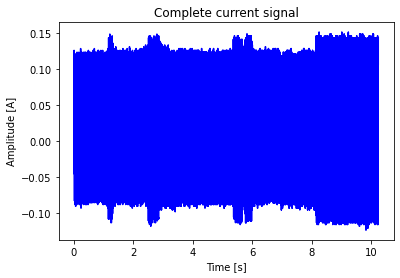

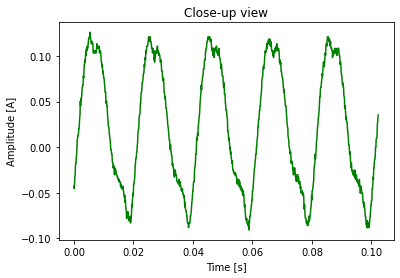

In [4]:
pyplot.figure(1)
pyplot.plot(t,x,'b')
pyplot.xlabel('Time [s]')
pyplot.ylabel('Amplitude [A]')
pyplot.title('Complete current signal')

pyplot.figure(2)
pyplot.plot(t[0:1000],x[0:1000],'g')
pyplot.xlabel('Time [s]')
pyplot.ylabel('Amplitude [A]')
pyplot.title('Close-up view')

## Calculating statistics
`Numpy` contains a number of useful functions for the calculation of statistical quantities. The following code segment extracts a sample of data points from the complete current signal and then calculates a number of statistical quantities:

In [5]:
sample = x[0:999]
standardDeviation = np.std(sample)
average = np.mean(sample)
median = np.median(sample)
median2 = np.quantile(sample,0.5)
Q1 = np.quantile(sample,0.25)
Q3 = np.quantile(sample,0.75)
IQR = Q3 - Q1
print('Standard deviation: ',standardDeviation,' A')
print('Variance: ',standardDeviation**2,' A^2')
print('Interquartile range: ',IQR,' A')
print('First quartile: ',Q1,' A')
print('Arithmetic mean: ',average,' A')
print('Median :',median, ' and ',median2,' A')
print('Third quartile: ',Q3,' A')

Standard deviation:  0.06776372281915802  A
Variance:  0.004591922130311677  A^2
Interquartile range:  0.133539101  A
First quartile:  -0.037794085  A
Arithmetic mean:  0.022976584262862865  A
Median : 0.01763724  and  0.01763724  A
Third quartile:  0.095745016  A


More information on `numpy` can be found at: https://numpy.org/doc/stable/user/absolute_beginners.html

## Loops
Some repetitive actions can be performed by either a `for` loop or a `while` loop. In the code segment below the AC current signal is rectified. 

**Note** that in Python loops and if-statements are indicated by indenting as you can see below.

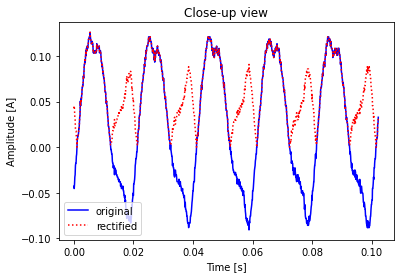

In [6]:
k = 0
new = np.zeros(1000)
while (k < 1000):
    if (x[k] < 0):
        new[k] = -1*x[k]
    else:
        new[k] = x[k]
    k = k + 1

pyplot.figure(3)
pyplot.plot(t[0:999],x[0:999],'b',label='original')
pyplot.plot(t[0:999],new[0:999],'r:',label='rectified')
pyplot.xlabel('Time [s]')
pyplot.ylabel('Amplitude [A]')
pyplot.title('Close-up view')
pyplot.legend()

It is important to note that significant performance improvements can be obtained by vectorizing the code (i.e. manipulating entire arrays) rather than working with each sample separately. The half-wave rectifier implemented by means of a while loop above can be executed much faster by rewriting the code as follows:

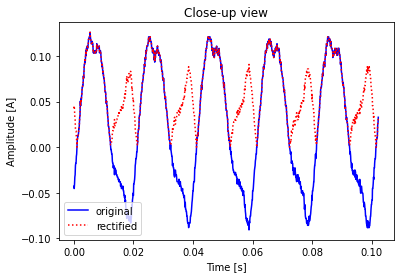

In [7]:
new2 = np.abs(x[0:1000])

pyplot.figure(4)
pyplot.plot(t[0:999],x[0:999],'b',label='original')
pyplot.plot(t[0:999],new2[0:999],'r:',label='rectified')
pyplot.xlabel('Time [s]')
pyplot.ylabel('Amplitude [A]')
pyplot.title('Close-up view')
pyplot.legend()

That is all for now folks. Due to the popularity of Python, help is ubiquitous on the internet. Just type your question (e.g. "how to calculate a fast fourier transform with Python") in either DuckDuckGo (https://duckduckgo.com) or Google and read the advice judiciously.